In [1]:
from typing_extensions import TypedDict
from langgraph.graph import StateGraph,START,END

# Reducer
from typing import Annotated
from langgraph.graph.message import add_messages

In [2]:
class State(TypedDict):
    messages:Annotated[list,add_messages]

In [4]:
import os
from dotenv import load_dotenv
load_dotenv()

os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")
os.environ["GOOGLE_API_KEY"]=os.getenv("GOOGLE_API_KEY")
os.environ["LANGCHAIN_API_KEY"]=os.getenv("LANGCHAIN_API_KEY")


In [5]:
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_groq import ChatGroq

llm1=ChatGroq(model="qwen/qwen3.8-27b")
llm2=ChatGoogleGenerativeAI(model="gemini-3.1-flash-lite")

In [6]:
llm1.invoke("Hello")

AIMessage(content='Hello! How can I help you today?', additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 10, 'prompt_tokens': 13, 'total_tokens': 23, 'completion_time': 0.021151127, 'completion_tokens_details': None, 'prompt_time': 0.00060592, 'prompt_tokens_details': None, 'queue_time': 0.05466109, 'total_time': 0.021757047}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_424cb89518', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1e2a2-2773-7252-942c-5102ae7f4c72-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 13, 'output_tokens': 10, 'total_tokens': 23})

In [7]:
llm2.invoke("Hello")

AIMessage(content=[{'type': 'text', 'text': 'Hello! How can I help you today?', 'extras': {'signature': 'EnMKcQFpFH0T3MJbsqRqP6bVdb0JwGN+1Iybz7EiXH+jL3nLAqG2A99HhI9aoz+9PattkaNl0hkpAbGMqByDEKzitgZbteCgFQT8ak1QS+AZv+hcmnbY/i8oV6OqFnYZIGIACahM7QR1qQGo0mpidn8MNzGp'}}], additional_kwargs={}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.1-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1e2a2-7047-75df-9565-7835af48cd6c-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 2, 'output_tokens': 9, 'total_tokens': 11, 'input_token_details': {'cache_read': 0}})

In [8]:
from langgraph.checkpoint.memory import MemorySaver
memory=MemorySaver()
def superbot(state:State):
    return{"messages":[llm1.invoke(state['messages'])]}

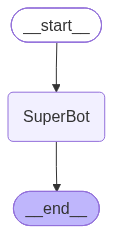

In [9]:
graph=StateGraph(State)
## nodes
graph.add_node("SuperBot",superbot)
##Edges
graph.add_edge(START,"SuperBot")
graph.add_edge("SuperBot",END)

graph_builder=graph.compile(checkpointer=memory)
#Display
from IPython.display import Image,display
display(Image(graph_builder.get_graph().draw_mermaid_png()))

In [10]:
config = {"configurable": {"thread_id": "1"}}

graph_builder.invoke({'messages':"Hi,My name is Hrishi And I like cricket"},config)

{'messages': [HumanMessage(content='Hi,My name is Hrishi And I like cricket', additional_kwargs={}, response_metadata={}, id='3befc3bd-c0ea-4b45-9ede-10b82f89ba22'),
  AIMessage(content='Hello Hrishi! It’s nice to meet you.\n\nCricket is a fantastic sport with so much strategy, skill, and excitement. Do you have a favorite team or player that you follow? Or perhaps there’s a specific aspect of the game (like batting, bowling, or fielding) that you enjoy the most?\n\nFeel free to share your thoughts, and I’d be happy to chat about the latest matches, stats, or even some fun cricket trivia! 🏏', additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 99, 'prompt_tokens': 23, 'total_tokens': 122, 'completion_time': 0.198380659, 'completion_tokens_details': None, 'prompt_time': 0.001347862, 'prompt_tokens_details': None, 'queue_time': 0.048505656, 'total_time': 0.199728521}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_21e59ac2de', 'service_tier': 'on_de

## Streaming

### .Stream

In [11]:
for chunk in graph_builder.stream({'messages':"I also like Football"},config,stream_mode="updates"):
    print(chunk)

{'SuperBot': {'messages': [AIMessage(content='That’s great, Hrishi! Having an interest in both cricket and football means you’re a true sports enthusiast. Both games have their unique charms—cricket with its tactical depth and long formats, and football with its fast pace and global reach.\n\nDo you have a favorite football team or league? And maybe a favorite player? I’d love to hear which side of the pitch (or field) you enjoy watching the most! ⚽🏏', additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 94, 'prompt_tokens': 139, 'total_tokens': 233, 'completion_time': 0.178793468, 'completion_tokens_details': None, 'prompt_time': 0.009687376, 'prompt_tokens_details': None, 'queue_time': 0.049327712, 'total_time': 0.188480844}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_21e59ac2de', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1e2e5-94b0-77d8-9526-c1daf9dc3e28-0', tool_calls=[

In [12]:
for chunk in graph_builder.stream({'messages':"I Love sports "},config,stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi,My name is Hrishi And I like cricket', additional_kwargs={}, response_metadata={}, id='3befc3bd-c0ea-4b45-9ede-10b82f89ba22'), AIMessage(content='Hello Hrishi! It’s nice to meet you.\n\nCricket is a fantastic sport with so much strategy, skill, and excitement. Do you have a favorite team or player that you follow? Or perhaps there’s a specific aspect of the game (like batting, bowling, or fielding) that you enjoy the most?\n\nFeel free to share your thoughts, and I’d be happy to chat about the latest matches, stats, or even some fun cricket trivia! 🏏', additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 99, 'prompt_tokens': 23, 'total_tokens': 122, 'completion_time': 0.198380659, 'completion_tokens_details': None, 'prompt_time': 0.001347862, 'prompt_tokens_details': None, 'queue_time': 0.048505656, 'total_time': 0.199728521}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_21e59ac2de', 'service_tier': 'on_dema

### aStream

In [13]:
config={"configurable":{"thread_id":"3"}}

async for event in graph_builder.astream_events({"messages":["Hi My name is Hrishi and I like to play cricket"]},config,version='v2'):
    print(event)

{'event': 'on_chain_start', 'data': {'input': {'messages': ['Hi My name is Hrishi and I like to play cricket']}}, 'name': 'LangGraph', 'tags': [], 'run_id': '01a1e2e9-9187-71e1-b38c-61566476b763', 'metadata': {'thread_id': '3', 'ls_integration': 'langgraph'}, 'parent_ids': []}
{'event': 'on_chain_start', 'data': {'input': {'messages': [HumanMessage(content='Hi My name is Hrishi and I like to play cricket', additional_kwargs={}, response_metadata={}, id='c3453c4c-3aab-4629-9850-b52dc2ef7aa1')]}}, 'name': 'SuperBot', 'tags': ['graph:step:1'], 'run_id': '01a1e2e9-918b-7473-a960-1541f011e4c5', 'metadata': {'thread_id': '3', 'ls_integration': 'langgraph', 'langgraph_step': 1, 'langgraph_node': 'SuperBot', 'langgraph_triggers': ('branch:to:SuperBot',), 'langgraph_path': ('__pregel_pull', 'SuperBot'), 'langgraph_checkpoint_ns': 'SuperBot:52e5c5a7-b10f-3b78-a730-d3a49d5c9dad'}, 'parent_ids': ['01a1e2e9-9187-71e1-b38c-61566476b763']}
{'event': 'on_chat_model_start', 'data': {'input': {'messages